In [1]:
library(zellkonverter)
library(SingleCellExperiment)
library(miloR)
library(scater)
library(Matrix)
library(dplyr)

Registered S3 method overwritten by 'zellkonverter':
  method                                             from      
  py_to_r.pandas.core.arrays.categorical.Categorical reticulate

Loading required package: SummarizedExperiment

Loading required package: MatrixGenerics

Loading required package: matrixStats


Attaching package: ‘MatrixGenerics’


The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,


In [2]:
plot_milo <- function(milo,da_results, res_column="logFC", plotfile=NA, cap=NA, fdr_cutoff=0.1, show=TRUE) {
    if (is.na(cap)) cap <- quantile(abs(da_results[res_column]), 0.9, na.rm=TRUE)
    cat("cap:", cap, "\n")

    # --- background cell UMAP from the Milo object ---
    umap <- as.data.frame(reducedDim(milo, "X_umap"))
    colnames(umap) <- c("UMAP1", "UMAP2")
    
    # --- get Milo neighborhood plot data ---
    p <- plotNhoodGraphDA(
      milo,
      da_results,
      alpha = 1,
      res_column = res_column,
      layout = "X_umap"
    )
    
    df <- p$data
    
    # map SpatialFDR onto plotted neighborhood nodes
    ix <- match(df$.ggraph.orig_index, da_results$Nhood)
    df$SpatialFDR <- da_results$SpatialFDR[ix]
    
    # use the plotted color column from plotNhoodGraphDA
    res_col <- "colour_by"
    
    # clamp extreme values for prettier coloring
    #cap <- quantile(abs(df[[res_col]]), 0.9, na.rm = TRUE)
    df[[res_col]] <- pmax(pmin(df[[res_col]], cap), -cap)
    
    # significance flag
    df$is_sig <- !is.na(df$SpatialFDR) & df$SpatialFDR <= fdr_cutoff


    ## Get x/y coord of each neighborhood
    
    # cell UMAP coordinates
    tmp_umap <- reducedDim(milo, "X_umap")
    colnames(tmp_umap) <- c("x", "y")
    
    # neighborhood membership matrix
    nh <- nhoods(milo)
    dim(nh)
    # usually: n_cells x n_neighborhoods
    
    # neighborhood sizes
    n_per_nhood <- Matrix::colSums(nh)
    
    # centroid coordinates for each neighborhood
    nhood_x <- as.numeric(Matrix::crossprod(nh, tmp_umap[, "x"])) / n_per_nhood
    nhood_y <- as.numeric(Matrix::crossprod(nh, tmp_umap[, "y"])) / n_per_nhood
    
    # build a table keyed by Nhood
    coords <- data.frame(
      Nhood = seq_len(ncol(nh)),
      x = nhood_x,
      y = nhood_y
    )
    
    # attach to da_results in the correct order
    ix <- match(da_results$Nhood, coords$Nhood)
    da_results$x <- coords$x[ix]
    da_results$y <- coords$y[ix]

    ## Also annotate cell types
    # cell type per cell
    ct <- as.character(colData(milo)$celltype)
    # sparse one-hot matrix: cells x celltypes
    ct_mat <- sparse.model.matrix(~ 0 + ct)
    colnames(ct_mat) <- sub("^ct", "", colnames(ct_mat))
    # counts of each cell type in each neighborhood:
    # (celltypes x neighborhoods)
    ct_counts <- crossprod(ct_mat, nh)

    # most common cell type index per neighborhood
    top_idx <- max.col(t(as.matrix(ct_counts)), ties.method = "first")
    # label of top cell type
    top_label <- rownames(ct_counts)[top_idx]
    
    # count of top cell type
    top_count <- ct_counts[cbind(top_idx, seq_len(ncol(ct_counts)))]
    top_count <- as.numeric(top_count)
    
    # fraction of neighborhood belonging to top type
    top_fraction <- top_count / n_per_nhood
    
    # result table
    nhood_annotation <- data.frame(
      Nhood = seq_len(ncol(nh)),
      celltype = top_label,
      celltype.fraction = top_fraction
    )
    ix <- match(da_results$Nhood, nhood_annotation$Nhood)
    da_results$celltype <- nhood_annotation$celltype[ix]
    da_results$celltype_fraction <- nhood_annotation$celltype.fraction[ix]
    f <- da_results$celltype_fraction < 0.7
    da_results[f,"celltype"] <- "Mixed"

    
    # get condition
    ct <- as.character(colData(milo)$condition)
    
    # sparse one-hot matrix: cells x conditions
    ct_mat <- sparse.model.matrix(~ 0 + ct)
    colnames(ct_mat) <- sub("^ct", "", colnames(ct_mat))
    
    # counts of each condition in each neighborhood:
    # conditions x neighborhoods
    ct_counts <- crossprod(ct_mat, nh)
    
    # most common condition index per neighborhood
    top_idx <- max.col(t(as.matrix(ct_counts)), ties.method = "first")
    
    # label of top condition
    top_label <- rownames(ct_counts)[top_idx]
    
    # count of top condition
    top_count <- ct_counts[cbind(top_idx, seq_len(ncol(ct_counts)))]
    top_count <- as.numeric(top_count)
    
    # fraction of neighborhood belonging to top condition
    top_fraction <- top_count / n_per_nhood
    
    # condition fractions for every neighborhood:
    # neighborhoods x conditions
    ct_fraction <- t(t(ct_counts) / n_per_nhood)
    
    # make condition-specific fraction column names
    rownames(ct_fraction) <- paste0("condition_fraction_", rownames(ct_fraction))
    
    # transpose to neighborhoods x conditions
    ct_fraction_df <- as.data.frame(t(as.matrix(ct_fraction)))
    
    # add Nhood column for matching
    ct_fraction_df$Nhood <- seq_len(ncol(nh))
    
    # result table
    nhood_annotation <- data.frame(
    Nhood = seq_len(ncol(nh)),
    condition = top_label,
    condition.fraction = top_fraction,
    check.names = FALSE
    )
    
    # add condition-specific fractions
    nhood_annotation <- cbind(
    nhood_annotation,
    ct_fraction_df[match(nhood_annotation$Nhood, ct_fraction_df$Nhood),
                 setdiff(colnames(ct_fraction_df), "Nhood"),
                 drop = FALSE]
    )
    
    ix <- match(da_results$Nhood, nhood_annotation$Nhood)
    
    da_results$condition <- nhood_annotation$condition[ix]
    da_results$condition_fraction <- nhood_annotation$condition.fraction[ix]
    
    # add one column per condition, e.g.
    # condition_fraction_P13, condition_fraction_STOP, condition_fraction_REF
    fraction_cols <- grep("^condition_fraction_", colnames(nhood_annotation), value = TRUE)
    
    da_results[, fraction_cols] <- nhood_annotation[ix, fraction_cols, drop = FALSE]

    p <- ggplot() +
      geom_point(
        data = umap,
        aes(x = UMAP1, y = UMAP2),
        color = "grey88",
        size = 3.0,
        alpha = 1,
          shape=16
      ) +
      geom_point(
        data = subset(df, !is_sig),
        aes(x = x, y = y),
        color = "grey60",
        size = 2.0,
        alpha = 1,
        shape = 16
      ) +
      geom_point(
        data = subset(df, is_sig)[order(abs(subset(df, is_sig)[[res_col]])), ],
        aes(x = x, y = y, color = .data[[res_col]]),
        size = 2,
        alpha = 0.95,
        shape = 16
      ) +
      scale_color_gradient2(
        low = "blue",
        mid = "white",
        high = "red",
        midpoint = 0,
        name = "logFC"
      ) +
      theme_void()
    if (show) print(p)
    if (!is.na(plotfile)) {
        cat("Saving", plotfile, "\n")
        ggsave(plotfile, width = 6, height = 5, dpi = 300)
    }
    return(da_results)
}

In [3]:
infile <- "NOBACKUP/adata_for_Milo_k100.h5ad"

In [4]:
pc <- "X_umap"
print(sprintf("PC = %s", pc))

[1] "PC = X_umap"


In [5]:
sce <- readH5AD(infile)

Warning message:
“The names of these selected obs columns have been modified to match R conventions: 'Macro Cell Type 1' -> 'Macro.Cell.Type.1', 'Macro Cell Type 2' -> 'Macro.Cell.Type.2', 'Macro Cell Type 3' -> 'Macro.Cell.Type.3', and 'Macro Cell
Type 4' -> 'Macro.Cell.Type.4'”


In [6]:
print(Sys.time())
print(sce)
print(Sys.time())

[1] "2026-11-20 21:33:46 EST"
class: SingleCellExperiment 
dim: 32245 149323 
metadata(1): neighbors
assays(1): X
rownames(32245): Xkr4 Gm1992 ... AC234645.1 AC149090.1
rowData names(9): gene_ids feature_types ... highly_variable_nbatches
  highly_variable_intersection
colnames(149323): AAACCATTCAGCATAT-K337_1 AAACCATTCCAGCTCC-K337_1 ...
  TGTGTTGAGGATTGAA-STOP_2 TGTGTTGAGGCTGTAC-STOP_2
colData names(74): sample library_size ... condition celltype
reducedDimNames(2): X_pca X_umap
mainExpName: NULL
altExpNames(0):
[1] "2026-11-20 21:33:48 EST"


In [7]:
reducedDims(sce)

List of length 2
names(2): X_pca X_umap

In [8]:
reducedDim(sce, "X_pca") <- reducedDim(sce, "X_pca")[, 1:26, drop = FALSE]

In [9]:
colData(sce)$sample <- as.character(colData(sce)$sample)
colData(sce)$condition <- as.character(colData(sce)$condition)

In [10]:
colPairNames(sce)

[1] "connectivities" "distances"

In [11]:
conn_name <- "connectivities"
dist_name <- "distances"
realk <- 100

In [12]:
connectivities <- colPair(sce, conn_name)
dist <- colPair(sce, dist_name)

In [13]:
dist_mat <- colPair(sce, dist_name, asSparse = TRUE)

In [14]:
# Make sure it is sparse numeric/logical
dist_mat <- as(dist_mat, "dgCMatrix")

In [15]:
# Binary topology: nonzero = edge
adj <- dist_mat
adj@x <- rep(1, length(adj@x))

In [16]:
# Optional but recommended: remove self-edges
diag(adj) <- 0
adj <- drop0(adj)

In [17]:
# Symmetrize as union of directed kNN edges.
# This avoids igraph's graph_from_adjacency_matrix(mode="max") path.
adj_sym <- (adj + Matrix::t(adj)) > 0
diag(adj_sym) <- 0
adj_sym <- drop0(adj_sym)

In [18]:
# Use only upper triangle so each undirected edge appears once
edge_idx <- summary(Matrix::triu(adj_sym, k = 1))

In [19]:
cell_names <- colnames(sce)
if (is.null(cell_names)) {
    cell_names <- as.character(seq_len(ncol(sce)))
    colnames(sce) <- cell_names
}

In [20]:
head(cell_names)

[1] "AAACCATTCAGCATAT-K337_1" "AAACCATTCCAGCTCC-K337_1"
[3] "AAACCATTCCATATCC-K337_1" "AAACCATTCGTCTCAT-K337_1"
[5] "AAACCATTCTAGGCCG-K337_1" "AAACCCGCAACATGGT-K337_1"

In [21]:
length(cell_names)

[1] 149323

In [22]:
edges <- data.frame(
    from = cell_names[edge_idx$i],
    to   = cell_names[edge_idx$j]
)

In [23]:
vertices <- data.frame(name = cell_names)

In [24]:
g <- igraph::graph_from_data_frame(
    d = edges,
    directed = FALSE,
    vertices = vertices
)

In [25]:
# Optional safety check
g <- igraph::simplify(g, remove.multiple = TRUE, remove.loops = TRUE)

In [26]:
milo <- Milo(sce)

graph(milo) <- g

# Use the original directed kNN degree as k, not the symmetrized degree.
k <- round(median(Matrix::rowSums(adj > 0)))
milo@.k <- as.integer(k)

In [27]:
k

[1] 99

__Note: k is slightly different than realk, proceed with realk__

In [28]:
summary(Matrix::rowSums(adj > 0))

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
     99      99      99      99      99      99 

In [29]:
cat(realk, "\n")
k=realk
milo@.k=realk

100 


In [30]:
reducedDimNames(sce)

[1] "X_pca"  "X_umap"

In [31]:
# 4) Define neighborhoods
print(Sys.time())
milo <- makeNhoods(milo, prop = 0.2, k = k, d = 26, refined = FALSE)
print(Sys.time())

[1] "2026-11-20 21:36:52 EST"


Checking valid object



[1] "2026-11-20 21:46:53 EST"


In [32]:
milo <- countCells(milo, meta.data = as.data.frame(colData(milo)), samples = "sample")

Checking meta.data validity

Counting cells in neighbourhoods



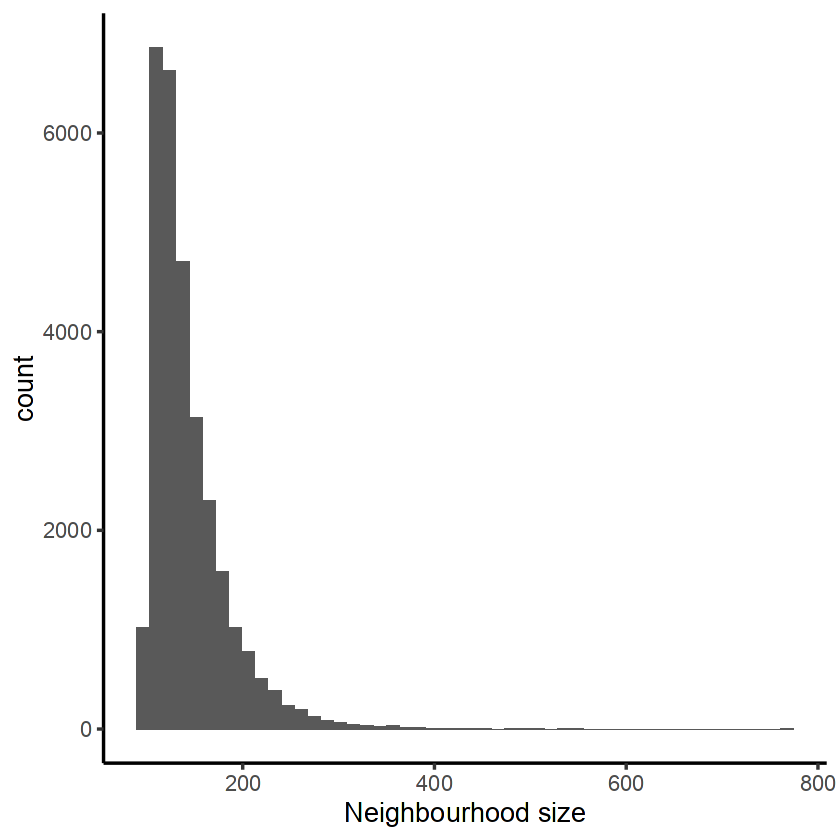

In [33]:
plotNhoodSizeHist(milo)

In [34]:
reducedDims(milo)

List of length 2
names(2): X_pca X_umap

In [35]:
# 6) Sample-level metadata for modeling
sample_df <- unique(as.data.frame(colData(milo))[, c("sample", "condition")])

# Make sure rownames match sample IDs
rownames(sample_df) <- sample_df$sample

# Check
sample_df

,sample,condition
,<chr>,<chr>
K337_1,K337_1,K337
K337_2,K337_2,K337
P13_1,P13_1,P13
P13_2,P13_2,P13
REF_1,REF_1,REF
REF_2,REF_2,REF
STOP_1,STOP_1,STOP
STOP_2,STOP_2,STOP


In [36]:
sample_df$condition <- factor(sample_df$condition)
sample_df$condition <- relevel(sample_df$condition, ref="REF")

In [37]:
mm <- model.matrix(~ 0 + condition, data = sample_df)
mm

,conditionREF,conditionK337,conditionP13,conditionSTOP
K337_1,0,1,0,0
K337_2,0,1,0,0
P13_1,0,0,1,0
P13_2,0,0,1,0
REF_1,1,0,0,0
REF_2,1,0,0,0
STOP_1,0,0,0,1
STOP_2,0,0,0,1


In [38]:
da_results <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionP13 - conditionSTOP"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [39]:
min(da_results$FDR)

[1] 0.9969951

In [40]:
min(da_results$PValue)

[1] 0.0008499327

In [41]:
da_results2 <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionP13 - conditionREF"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [42]:
min(da_results2$PValue)

[1] 0.001475722

In [43]:
min(da_results2$FDR)

[1] 0.9992394

In [44]:
da_results3 <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionSTOP - conditionREF"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [45]:
min(da_results3$FDR)

[1] 0.7332685

In [46]:
min(da_results3$PValue)

[1] 0.0003567878

In [47]:
da_results4 <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionK337 - conditionSTOP"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [48]:
min(da_results4$FDR)

[1] 0.1973648

In [49]:
min(da_results4$PValue)

[1] 0.0001029374

In [50]:
da_results5 <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionK337 - conditionREF"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [51]:
min(da_results5$PValue)

[1] 0.0004721669

In [52]:
min(da_results5$FDR)

[1] 0.3936921

In [53]:
da_results6 <- testNhoods(milo, design = ~ 0 + condition,
                         design.df = sample_df,
                         model.contrasts=c("conditionP13 - conditionK337"),
                         reduced.dim="X_pca",
                        fdr.weighting="graph-overlap")

Using TMM normalisation

Performing spatial FDR correction with graph-overlap weighting



In [54]:
min(da_results6$FDR)

[1] 0.4932373

In [55]:
min(da_results6$PValue)

[1] 0.0006565244

In [56]:
colData(milo)$celltype <- colData(milo)$Macro.Cell.Type.4

In [57]:
da_results <- annotateNhoods(milo, da_results, coldata_col = "celltype")
head(da_results %>% arrange(FDR))

,logFC,logCPM,F,PValue,FDR,Nhood,SpatialFDR,celltype,celltype_fraction
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>
1,-0.2635142,5.322059,0.11024735,0.7461308,0.9969951,1,0.9965831,Neutrophil,1.0000000
2,-1.0183088,5.289128,1.45834875,0.2526907,0.9969951,2,0.9965831,Neutrophil,1.0000000
3,0.2194841,5.875867,0.06336231,0.8059386,0.9969951,3,0.9965831,Fibroblasts,0.7772727
4,-0.2147675,5.105468,0.05913253,0.8124207,0.9969951,4,0.9965831,Endothelial cells,0.9843750
5,-0.4658058,4.990567,0.27841396,0.6084203,0.9969951,5,0.9965831,Neutrophil,1.0000000
6,-0.3211381,4.854851,0.24236687,0.6322223,0.9969951,6,0.9965831,T cells,0.6000000


In [58]:
print(Sys.time())
milo <- buildNhoodGraph(milo)
print(Sys.time())

[1] "2026-11-20 21:52:11 EST"
[1] "2026-11-20 21:54:24 EST"


In [59]:
dir.create("milo_results")

cap: 1.518974 
Saving milo_results/milo_P13_vs_STOP_n30_fdr_0.25_k100.png 


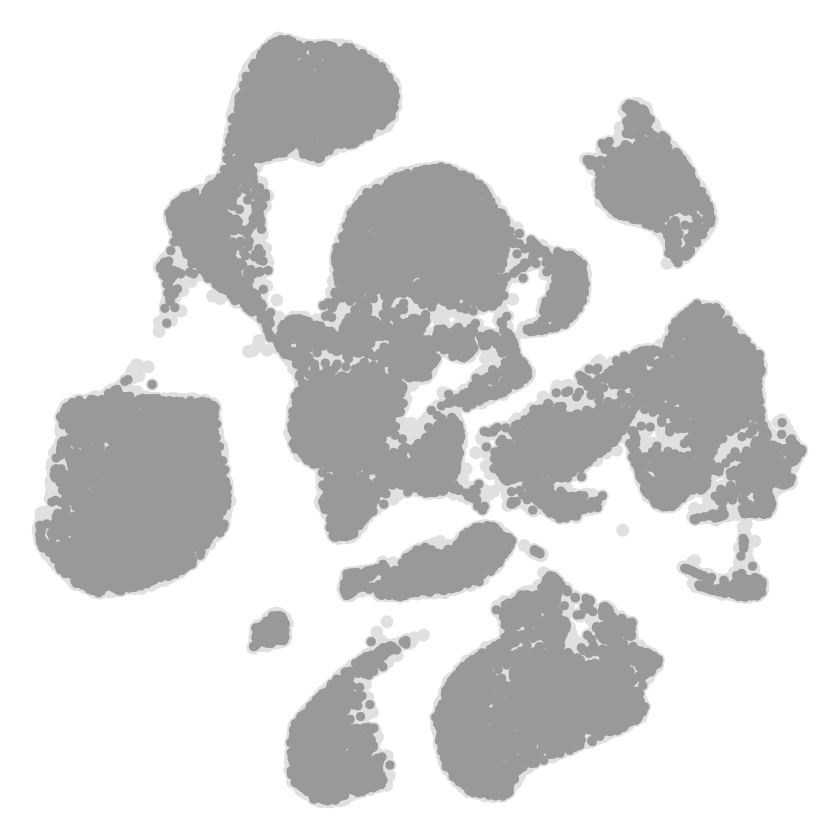

In [60]:
da_results <- plot_milo(milo,da_results, res_column="logFC", plotfile="milo_results/milo_P13_vs_STOP_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

In [61]:
head(da_results)

,logFC,logCPM,F,PValue,FDR,Nhood,SpatialFDR,celltype,celltype_fraction,x,y,condition,condition_fraction,condition_fraction_K337,condition_fraction_P13,condition_fraction_REF,condition_fraction_STOP
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,-0.2635142,5.322059,0.11024735,0.7461308,0.9969951,1,0.9965831,Neutrophil,1.0000000,-11.373055,1.342893,K337,0.5448276,0.5448276,0.1379310,0.1724138,0.1448276
2,-1.0183088,5.289128,1.45834875,0.2526907,0.9969951,2,0.9965831,Neutrophil,1.0000000,-6.188330,5.522459,REF,0.4000000,0.1161290,0.1677419,0.4000000,0.3161290
3,0.2194841,5.875867,0.06336231,0.8059386,0.9969951,3,0.9965831,Fibroblasts,0.7772727,4.089230,3.471314,K337,0.3909091,0.3909091,0.1909091,0.2727273,0.1454545
4,-0.2147675,5.105468,0.05913253,0.8124207,0.9969951,4,0.9965831,Endothelial cells,0.9843750,3.405038,14.620169,K337,0.3593750,0.3593750,0.2812500,0.0781250,0.2812500
5,-0.4658058,4.990567,0.27841396,0.6084203,0.9969951,5,0.9965831,Neutrophil,1.0000000,-9.955520,1.053635,K337,0.3414634,0.3414634,0.1951220,0.2113821,0.2520325
6,-0.3211381,4.854851,0.24236687,0.6322223,0.9969951,6,0.9965831,Mixed,0.6000000,17.716121,-6.901615,STOP,0.3545455,0.1272727,0.3181818,0.2000000,0.3545455


cap: 1.463001 
Saving milo_results/milo_P13_vs_REF_n30_fdr_0.25_k100.png 


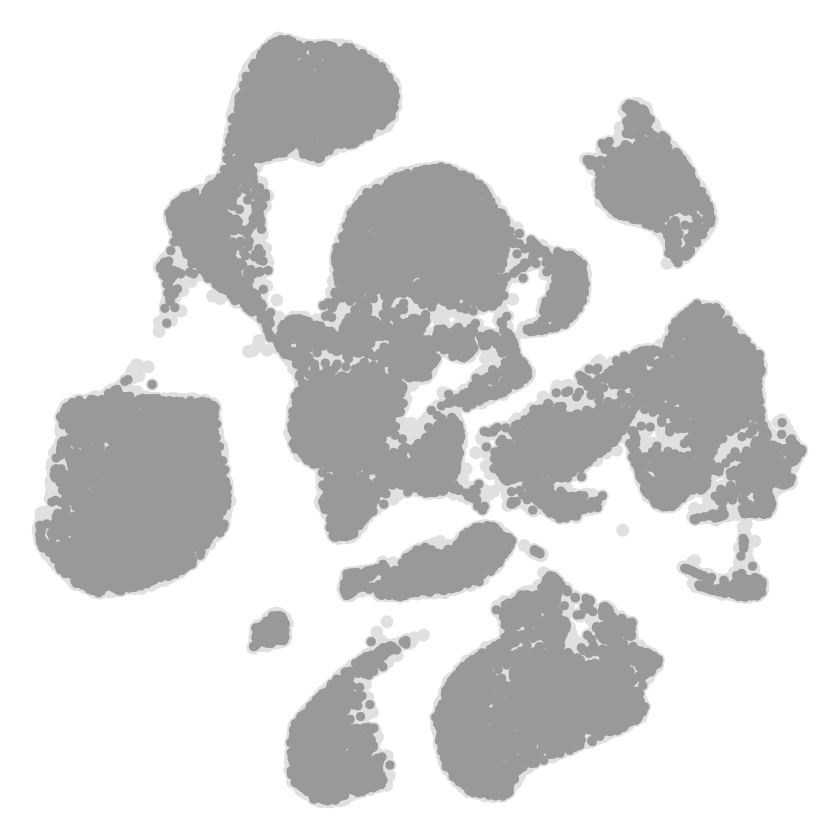

In [62]:
df <- plot_milo(milo,da_results2, res_column="logFC", plotfile="milo_results/milo_P13_vs_REF_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

cap: 1.804879 
Saving milo_results/milo_STOP_vs_REF_n30_fdr_0.25_k100.png 


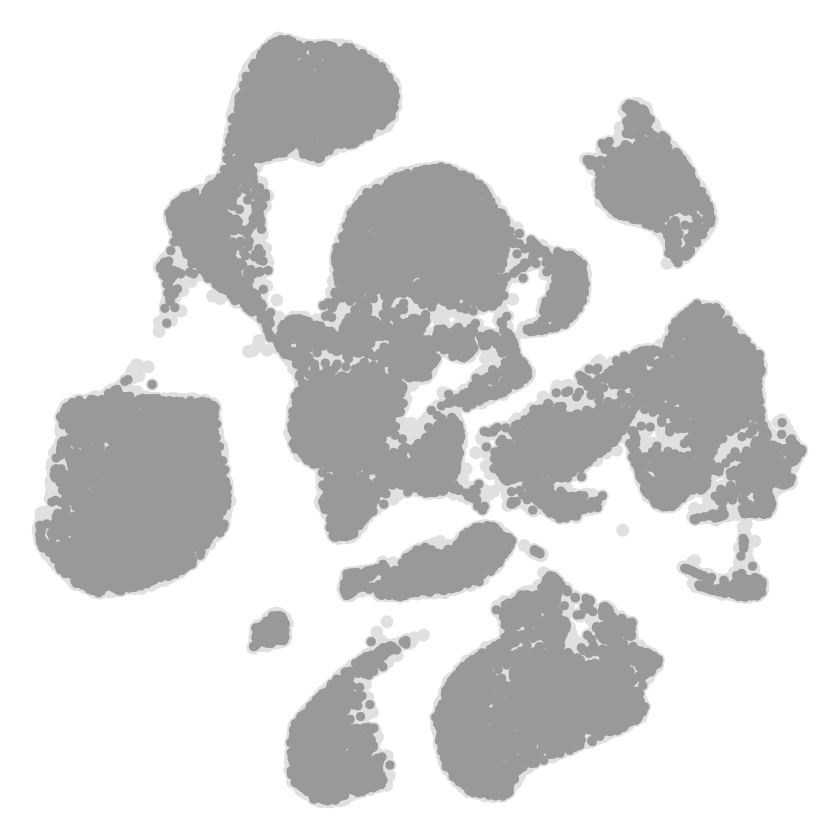

In [63]:
df <- plot_milo(milo,da_results3, res_column="logFC", plotfile="milo_results/milo_STOP_vs_REF_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

cap: 2.756713 
Saving milo_results/milo_K337_vs_STOP_n30_fdr_0.25_k100.png 


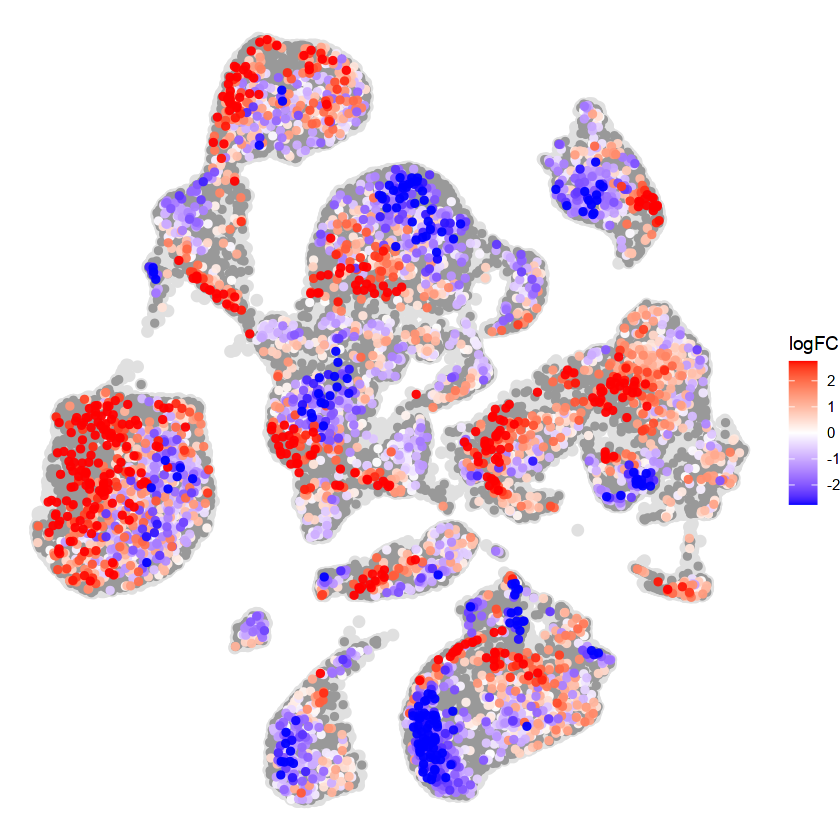

In [64]:
df <- plot_milo(milo,da_results4, res_column="logFC", plotfile="milo_results/milo_K337_vs_STOP_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

cap: 2.321419 
Saving milo_results/milo_K337_vs_REF_n30_fdr_0.25_k100.png 


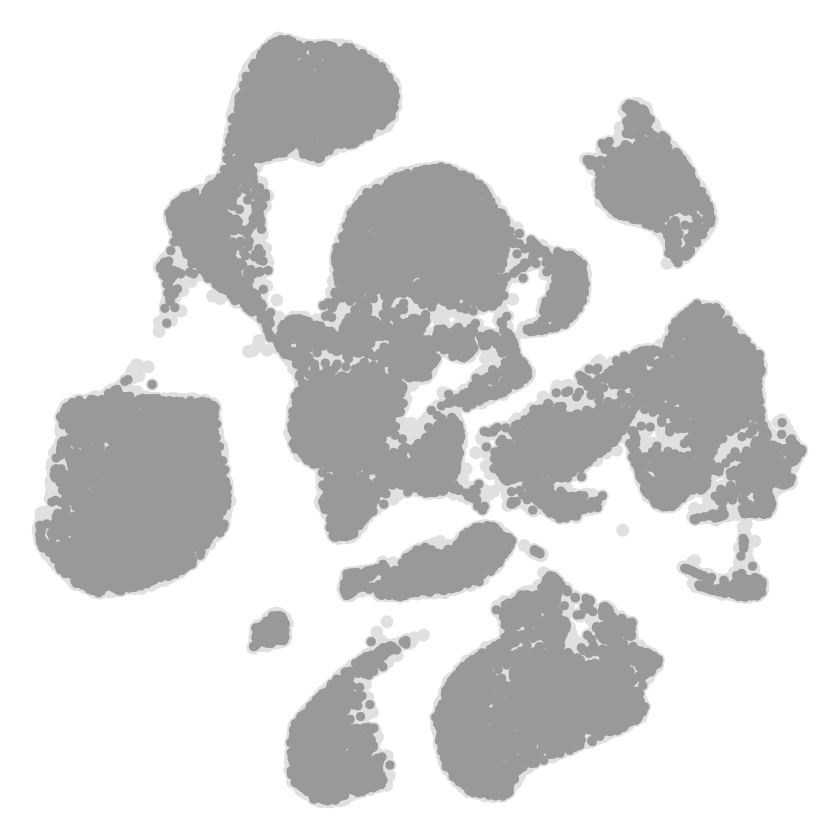

In [65]:
df <- plot_milo(milo,da_results5, res_column="logFC", plotfile="milo_results/milo_K337_vs_REF_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

cap: 2.170979 
Saving milo_results/milo_P13_vs_K337_n30_fdr_0.25_k100.png 


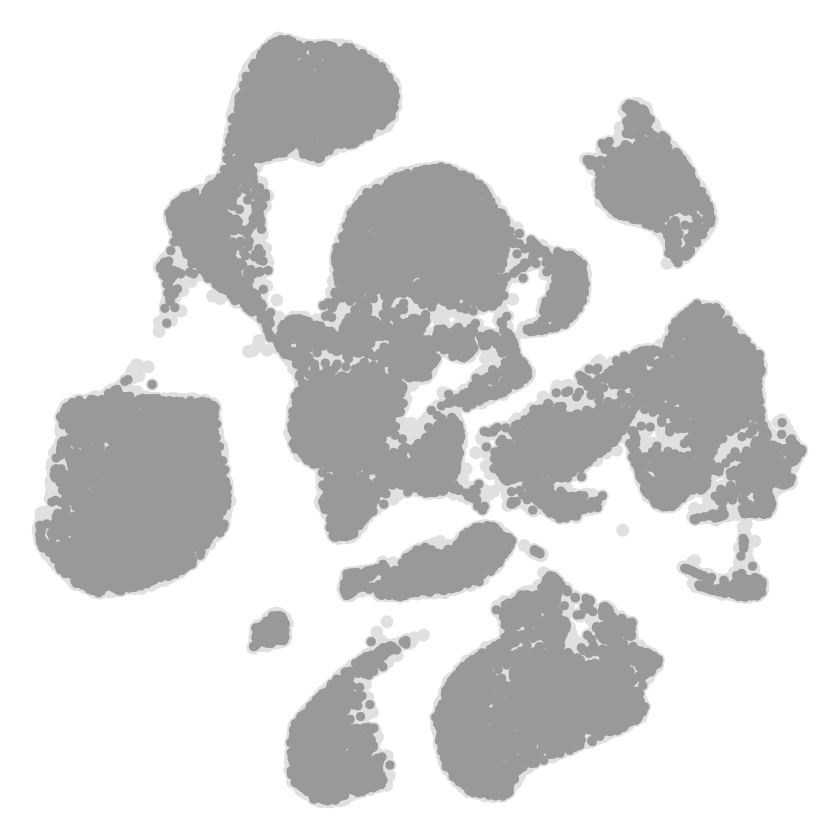

In [66]:
df <- plot_milo(milo,da_results6, res_column="logFC", plotfile="milo_results/milo_P13_vs_K337_n30_fdr_0.25_k100.png", cap=NA, fdr_cutoff=0.25, show=TRUE)

cap: 1.518974 
Saving milo_results/milo_P13_vs_STOP_n30_fdr_1.00_k100.png 


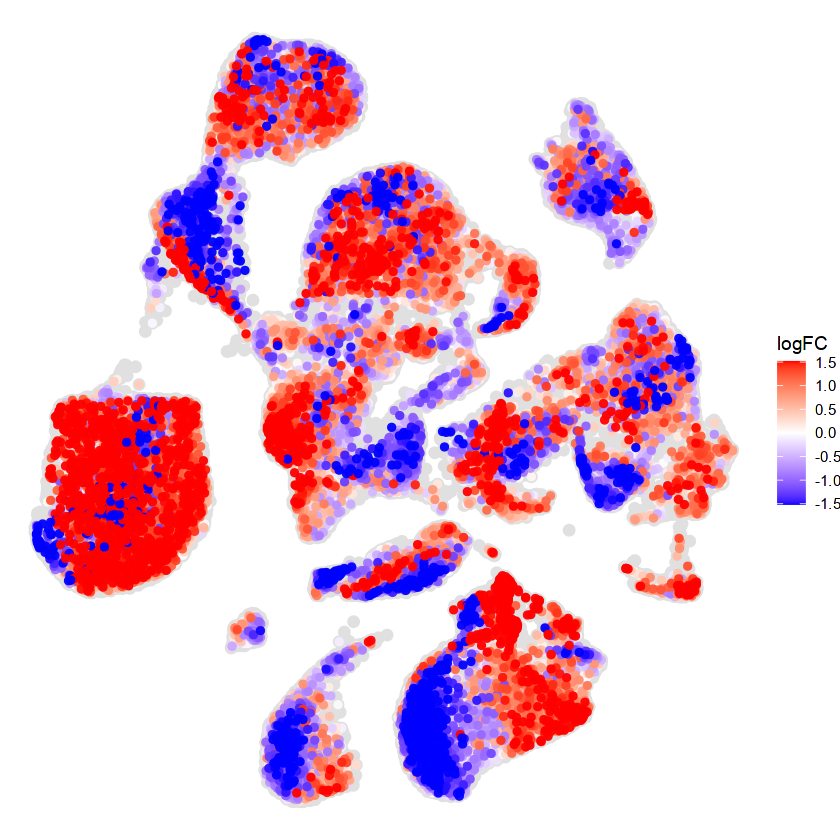

In [67]:
da_results <- plot_milo(milo,da_results, res_column="logFC", plotfile="milo_results/milo_P13_vs_STOP_n30_fdr_1.00_k100.png", cap=NA, fdr_cutoff=1.0, show=TRUE)

cap: 1.463001 
Saving milo_results/milo_P13_vs_REF_n30_fdr_1.00_k100.png 


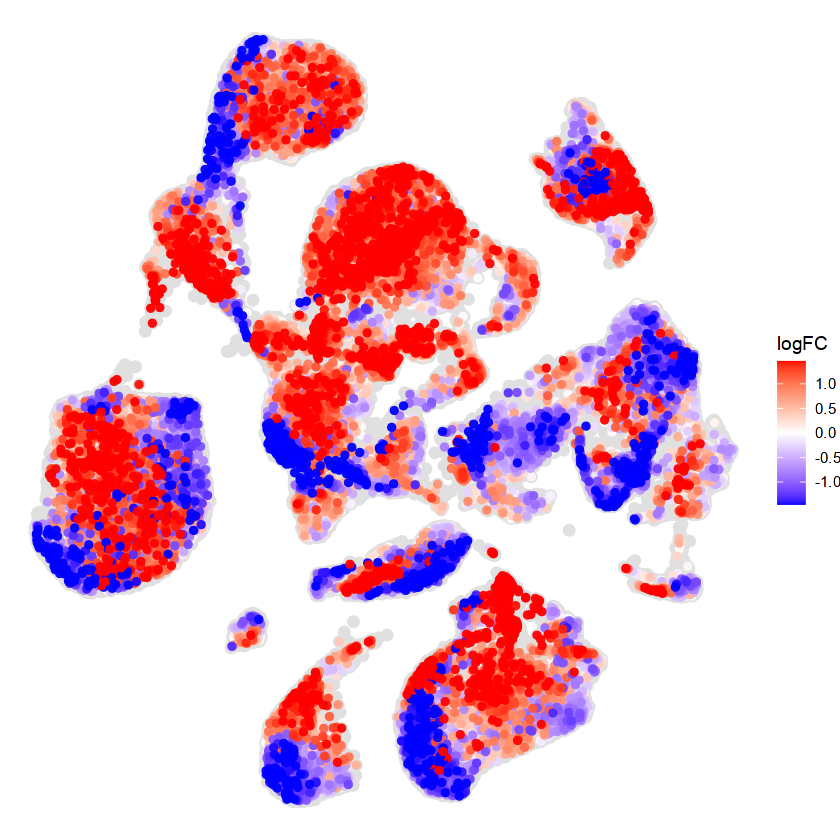

In [68]:
df <- plot_milo(milo,da_results2, res_column="logFC", plotfile="milo_results/milo_P13_vs_REF_n30_fdr_1.00_k100.png", cap=NA, fdr_cutoff=01.0, show=TRUE)

cap: 1.804879 
Saving milo_results/milo_STOP_vs_REF_n30_fdr_1.00_k100.png 


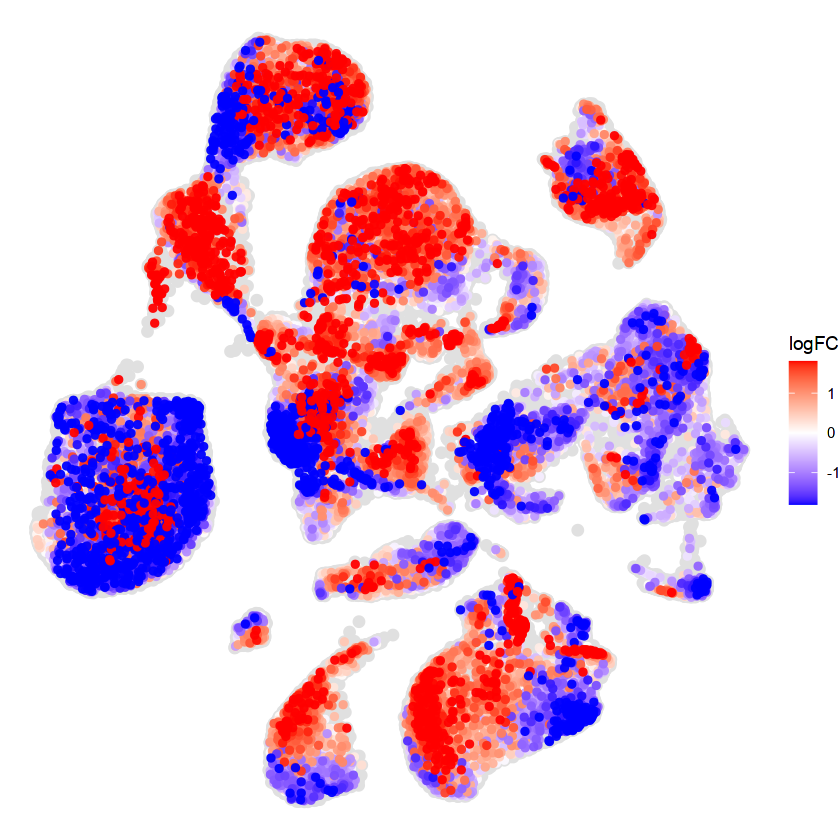

In [69]:
df <- plot_milo(milo,da_results3, res_column="logFC", plotfile="milo_results/milo_STOP_vs_REF_n30_fdr_1.00_k100.png", cap=NA, fdr_cutoff=1.0, show=TRUE)

cap: 2.756713 
Saving milo_results/milo_K337_vs_STOP_n30_fdr_1.0_k100.png 


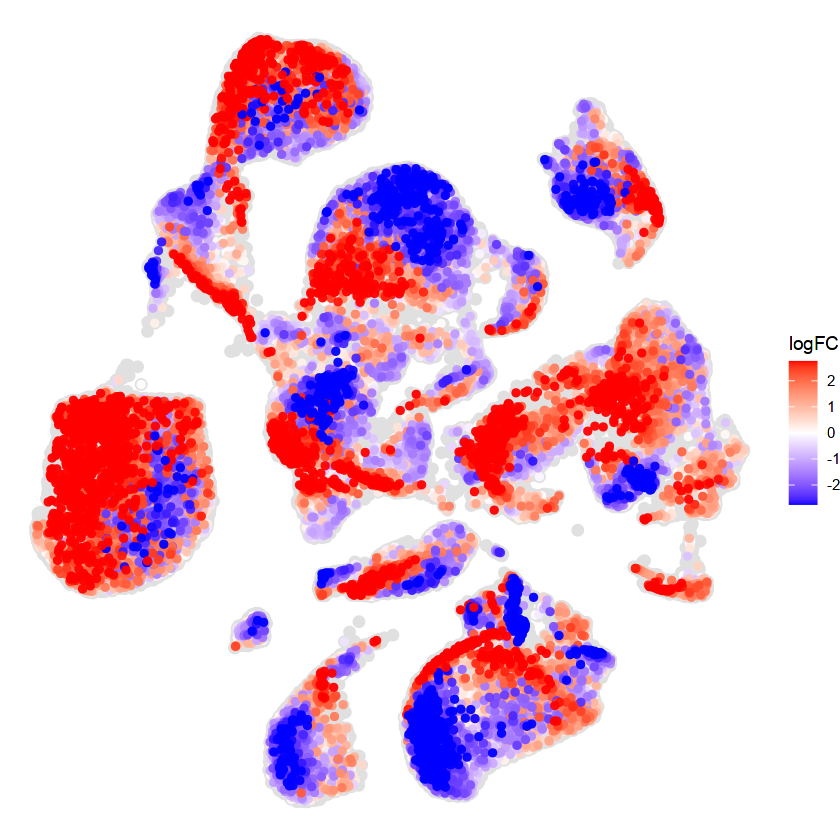

In [70]:
df <- plot_milo(milo,da_results4, res_column="logFC", plotfile="milo_results/milo_K337_vs_STOP_n30_fdr_1.0_k100.png", cap=NA, fdr_cutoff=1.0, show=TRUE)

cap: 2.321419 
Saving milo_results/milo_K337_vs_REF_n30_fdr_1.00_k100.png 


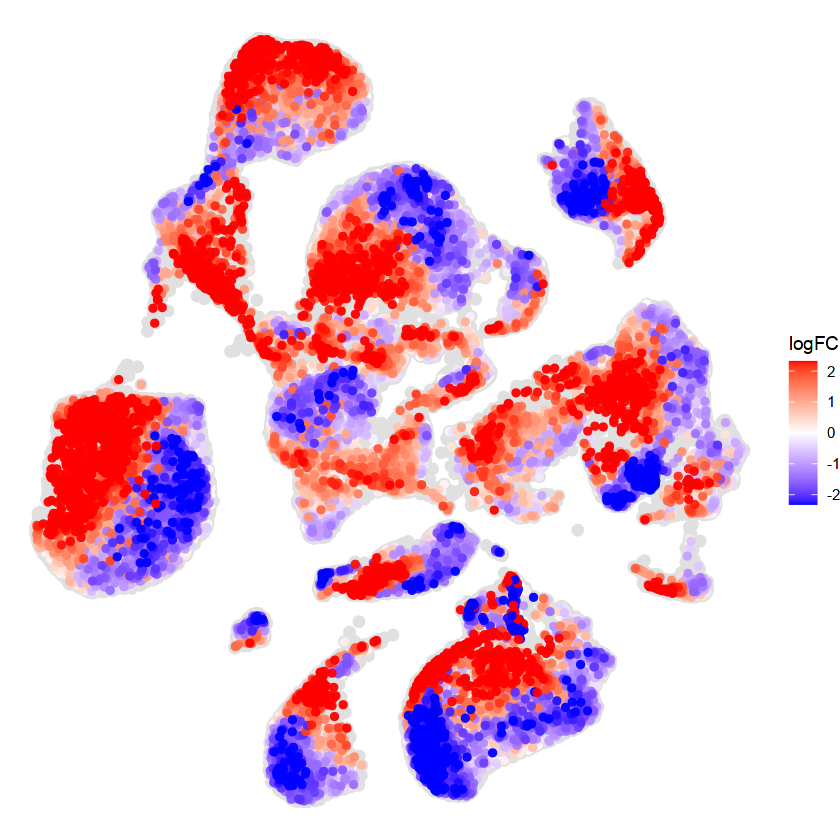

In [71]:
df <- plot_milo(milo,da_results5, res_column="logFC", plotfile="milo_results/milo_K337_vs_REF_n30_fdr_1.00_k100.png", cap=NA, fdr_cutoff=1.0, show=TRUE)

cap: 2.170979 
Saving milo_results/milo_P13_vs_K337_n30_fdr_1.00_k100.png 


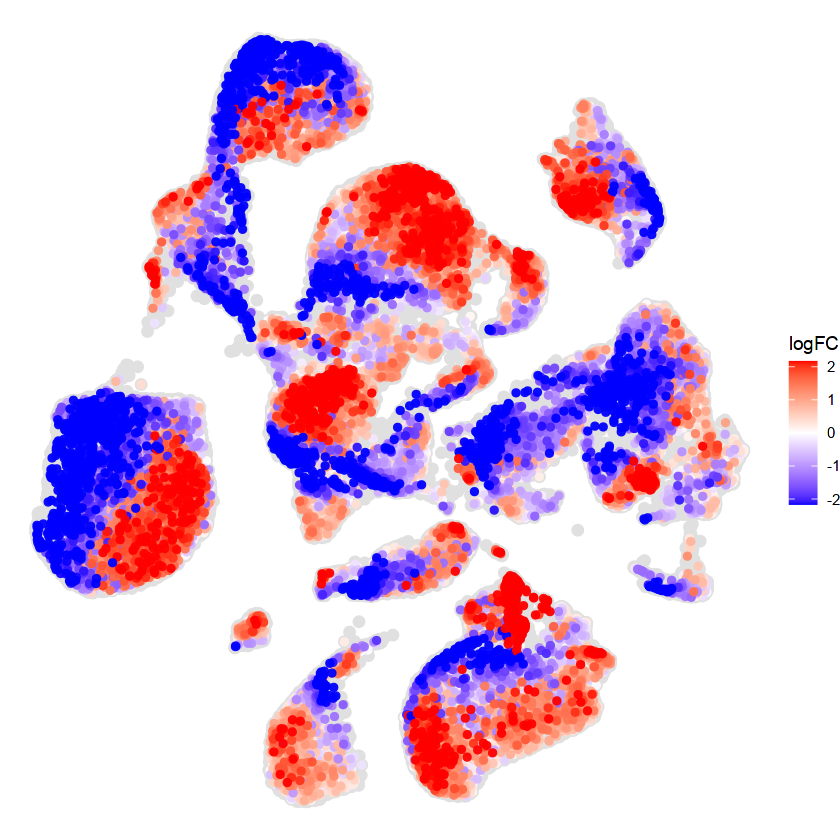

In [72]:
df <- plot_milo(milo,da_results6, res_column="logFC", plotfile="milo_results/milo_P13_vs_K337_n30_fdr_1.00_k100.png", cap=NA, fdr_cutoff=1.0, show=TRUE)

In [73]:
write.csv(da_results, "milo_results/milo_da_results_all_P13_vs_STOP_k100.csv", row.names = FALSE)
write.csv(da_results2, "milo_results/milo_da_results_all_P13_vs_REF_k100.csv", row.names = FALSE)
write.csv(da_results3, "milo_results/milo_da_results_all_STOP_vs_REF_k100.csv", row.names = FALSE)
write.csv(da_results4, "milo_results/milo_da_results_all_K337_vs_STOP_k100.csv", row.names = FALSE)
write.csv(da_results5, "milo_results/milo_da_results_all_K337_vs_REF_k100.csv", row.names = FALSE)
write.csv(da_results6, "milo_results/milo_da_results_all_P13_vs_K337_k100.csv", row.names = FALSE)

In [74]:
library(data.table)
nh_long <- as.data.table(summary(nh))
# summary(nh) gives:
# i = row index, j = column index, x = value
# For neighborhood membership, x is usually 1 and can be dropped
nh_long[, cell := rownames(nh)[i]]
nh_long[, Nhood := j]

nh_long <- nh_long[, .(cell, Nhood)]

fwrite(nh_long, "milo_results/milo_all_k100_membership.tsv.gz", sep = "\t")


Attaching package: ‘data.table’


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:SummarizedExperiment’:

    shift


The following object is masked from ‘package:GenomicRanges’:

    shift


The following object is masked from ‘package:IRanges’:

    shift


The following objects are masked from ‘package:S4Vectors’:

    first, second




ERROR: Error in h(simpleError(msg, call)): error in evaluating the argument 'object' in selecting a method for function 'summary': object 'nh' not found
